<a href="https://colab.research.google.com/github/StepiciEduard/2026SIVA/blob/main/Lab2_CV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import glob as gl
import random
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
base_path = "/content/drive/MyDrive/CV1F/Images/Images"
images = []

for i in range(4):
  images.append(gl.glob(base_path+'/'+str(i)+'/*.jpg'))
print(images[0])



['/content/drive/MyDrive/CV1F/Images/Images/0/0.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/1.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/2.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/3.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/4.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/5.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/7.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/6.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/8.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/9.jpg']


In [ ]:
random.seed(42)

random_list = random.sample(range(0, 9), 7)

train_images = []
test_images = []

for idx in range(4):
  tmp_train = []
  tmp_test = []
  for i in range(10):
    if i in random_list:
      tmp_train.append(images[idx][i])
    else:
      tmp_test.append(images[idx][i])
  train_images.append(tmp_train)
  test_images.append(tmp_test)

print(random_list)
print(test_images)
print(train_images)


[1, 0, 5, 2, 8, 4, 7]
[['/content/drive/MyDrive/CV1F/Images/Images/0/3.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/7.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/9.jpg'], ['/content/drive/MyDrive/CV1F/Images/Images/1/3.jpg', '/content/drive/MyDrive/CV1F/Images/Images/1/6.jpg', '/content/drive/MyDrive/CV1F/Images/Images/1/9.jpg'], ['/content/drive/MyDrive/CV1F/Images/Images/2/3.jpg', '/content/drive/MyDrive/CV1F/Images/Images/2/6.jpg', '/content/drive/MyDrive/CV1F/Images/Images/2/9.jpg'], ['/content/drive/MyDrive/CV1F/Images/Images/3/3.jpg', '/content/drive/MyDrive/CV1F/Images/Images/3/5.jpg', '/content/drive/MyDrive/CV1F/Images/Images/3/9.jpg']]
[['/content/drive/MyDrive/CV1F/Images/Images/0/0.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/1.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/2.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/4.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/5.jpg', '/content/drive/MyDrive/CV1F/Images/Images/0/6.jpg', '/content/dri

In [ ]:
tr_im = []
te_im = []

for i in range(len(train_images)):
  tmp = []
  for j in range(len(train_images[0])):
    im = cv2.imread(train_images[i][j])
    tmp.append(im)
  tr_im.append(tmp)

In [ ]:
import matplotlib.pyplot as plt


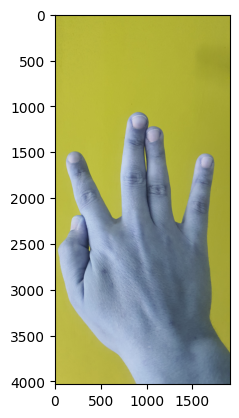

In [ ]:
plt.imshow(tr_im[0][0])

In [ ]:
for i in range(len(tr_im)):
  for j in range(len(tr_im[0])):
    tr_im[i][j] = cv2.cvtColor(tr_im[i][j], cv2.COLOR_BGR2RGB)

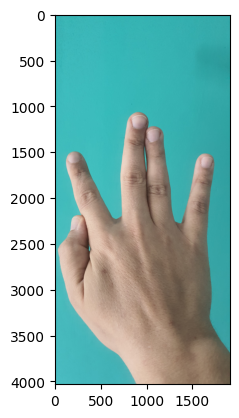

In [ ]:
plt.imshow(tr_im[0][0])

In [ ]:
scale_percent = 0.15
width = int(tr_im[0][0].shape[1] * scale_percent)
height = int(tr_im[0][0].shape[0] * scale_percent)
dim = (width, height)

for i in range(len(tr_im)):
  for j in range(len(tr_im[0])):
    tr_im[i][j] = cv2.resize(tr_im[i][j],dim)

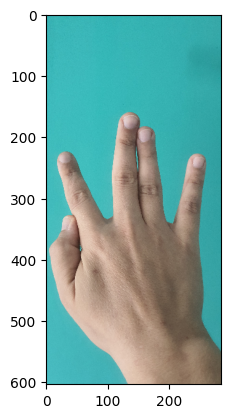

In [ ]:
plt.imshow(tr_im[0][0])

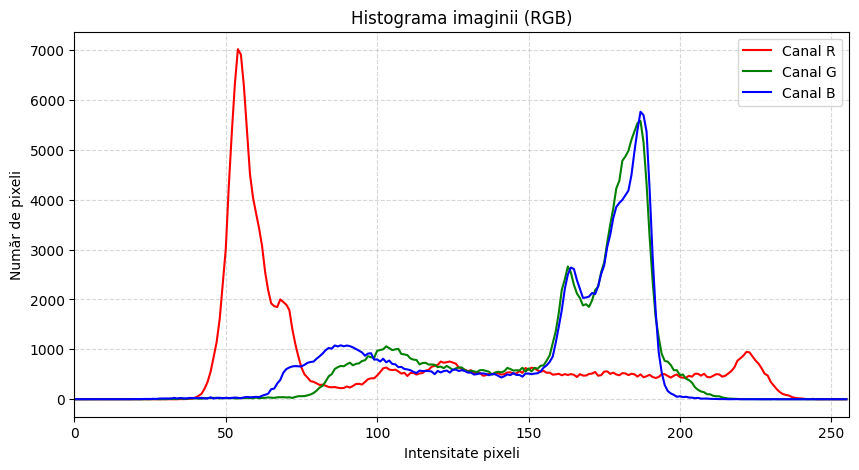

In [79]:
import cv2
import matplotlib.pyplot as plt

# Imaginea tr_im[0][0] este deja în format RGB
img = tr_im[0][0]
colors = ('r', 'g', 'b')

plt.figure(figsize=(10, 5))
plt.title('Histograma imaginii (RGB)')
plt.xlabel('Intensitate pixeli')
plt.ylabel('Număr de pixeli')

for i, color in enumerate(colors):
    # Calculăm histograma pentru fiecare canal
    hist = cv2.calcHist([img], [i], None, [256], [0, 256])
    plt.plot(hist, color=color, label=f'Canal {color.upper()}')
    plt.xlim([0, 256])

plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

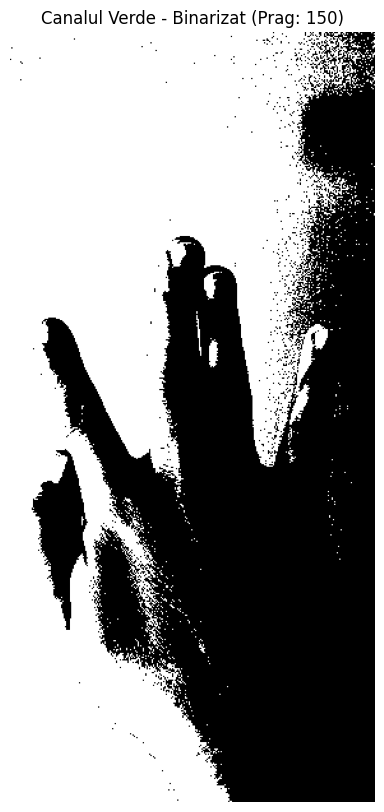

In [82]:
import cv2
import matplotlib.pyplot as plt

# Imaginea tr_im[0][0] este în format RGB, deci canalul verde este la indexul 1
img_rgb = tr_im[0][0]
green_channel = img_rgb[:, :, 1]

# Aplicăm pragul de binarizare la valoarea 150
# Pixelii cu valoare mai mare de 150 devin 255 (alb), iar restul 0 (negru)
_, binary_image = cv2.threshold(green_channel, 170, 255, cv2.THRESH_BINARY)

# Afișăm imaginea binarizată
plt.figure(figsize=(6, 10))
plt.imshow(binary_image, cmap='gray')
plt.title('Canalul Verde - Binarizat (Prag: 150)')
plt.axis('off')
plt.show()

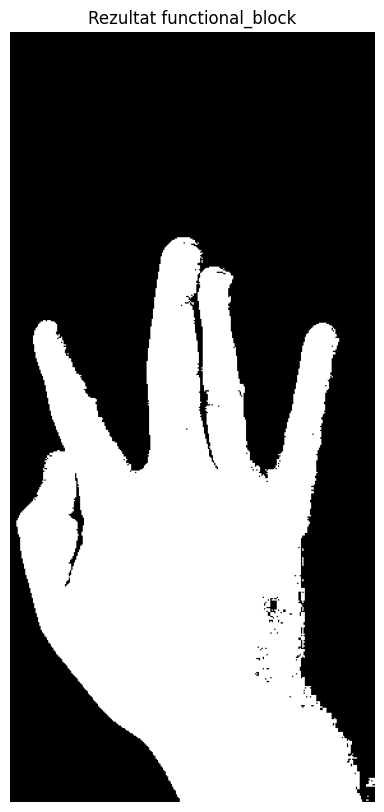

In [83]:
import numpy as np
import matplotlib.pyplot as plt

def functional_block(img):
    R = img[:,:,0]
    G = img[:,:,1]
    B = img[:,:,2]
    C1 = np.zeros((img.shape[0], img.shape[1]))
    C2 = np.zeros((img.shape[0], img.shape[1]))
    C3 = np.zeros((img.shape[0], img.shape[1]))
    C4 = np.zeros((img.shape[0], img.shape[1]))
    C5 = np.zeros((img.shape[0], img.shape[1]))
    C6 = np.zeros((img.shape[0], img.shape[1]))
    C7 = np.zeros((img.shape[0], img.shape[1]))
    rez = np.zeros((img.shape[0], img.shape[1]))

    C1[np.logical_and(np.logical_and(R > 95, G > 40), B > 20)] = 1
    C2[(np.maximum(np.maximum(R, G), B) - np.minimum(np.minimum(R, G), B)) > 15] = 1
    C3[np.absolute(R - G) > 15] = 1
    C4[np.logical_and(R > G, R > B)] = 1
    C5[np.logical_and(np.logical_and(R > 220, G > 210), B > 170)] = 1
    C6[np.absolute(R - G) <= 15] = 1
    C7[np.logical_and(R > B, G > B)] = 1

    caz1 = np.logical_and(np.logical_and(np.logical_and(C1 == 1, C2 == 1), C3 == 1), C4 == 1)
    caz2 = np.logical_and(np.logical_and(C5 == 1, C6 == 1), C7 == 1)
    rez[np.logical_or(caz1 == 1, caz2 == 1)] = 1
    return rez

# Aplicăm funcția pe imaginea curentă
img_output = functional_block(tr_im[0][0])

# Afișăm rezultatul
plt.figure(figsize=(6, 10))
plt.imshow(img_output, cmap='gray')
plt.title('Rezultat functional_block')
plt.axis('off')
plt.show()

In [84]:
# 1. Încărcăm imaginile de test în te_im
te_im = []
for i in range(len(test_images)):
    tmp = []
    for j in range(len(test_images[0])):
        im = cv2.imread(test_images[i][j])
        tmp.append(im)
    te_im.append(tmp)

# 2. Convertim imaginile de test din BGR în RGB și le redimensionăm
for i in range(len(te_im)):
    for j in range(len(te_im[0])):
        te_im[i][j] = cv2.cvtColor(te_im[i][j], cv2.COLOR_BGR2RGB)
        te_im[i][j] = cv2.resize(te_im[i][j], dim)

print("Imaginile de test au fost încărcate, convertite în RGB și redimensionate.")

Imaginile de test au fost încărcate, convertite în RGB și redimensionate.


In [85]:
# 3. Aplicăm funcția functional_block pentru toate imaginile de train și test
train_segmented = []
for i in range(len(tr_im)):
    tmp = []
    for j in range(len(tr_im[0])):
        segmented = functional_block(tr_im[i][j])
        tmp.append(segmented)
    train_segmented.append(tmp)

test_segmented = []
for i in range(len(te_im)):
    tmp = []
    for j in range(len(te_im[0])):
        segmented = functional_block(te_im[i][j])
        tmp.append(segmented)
    test_segmented.append(tmp)

print(f"Segmentare completă! Am procesat {len(train_segmented) * len(train_segmented[0])} imagini de train și {len(test_segmented) * len(test_segmented[0])} imagini de test.")

Segmentare completă! Am procesat 28 imagini de train și 12 imagini de test.


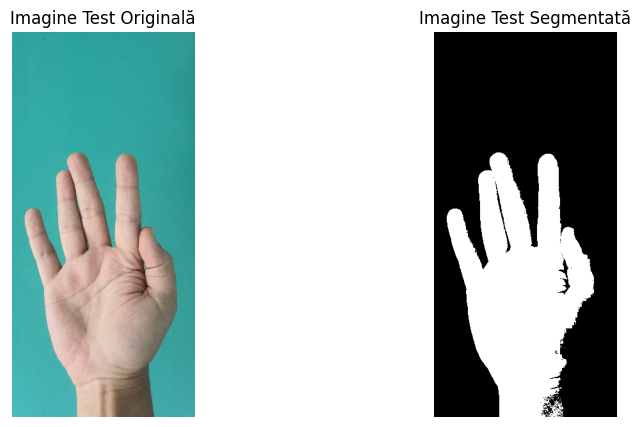

In [86]:
# 4. Afișăm un exemplu din setul de test pentru a verifica rezultatul
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(te_im[0][0])
plt.title('Imagine Test Originală')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(test_segmented[0][0], cmap='gray')
plt.title('Imagine Test Segmentată')
plt.axis('off')

plt.show()

In [87]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def keep_largest_contour(segmented_img):
    # Deoarece findContours funcționează pe imagini de tip uint8 pe 8 biți,
    # convertim masca din float64 (0.0 / 1.0) în uint8 (0 / 255).
    binary_img = (segmented_img * 255).astype(np.uint8)

    # Găsim contururile în imaginea binară
    contours, _ = cv2.findContours(binary_img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Creăm o mască goală cu aceeași dimensiune
    mask_largest = np.zeros_like(binary_img)

    if len(contours) > 0:
        # Identificăm conturul cu cea mai mare arie
        largest_contour = max(contours, key=cv2.contourArea)
        # Desenăm doar cel mai mare contur pe masca goală (-1 înseamnă umplerea conturului)
        cv2.drawContours(mask_largest, [largest_contour], -1, 255, thickness=cv2.FILLED)

    return mask_largest / 255.0  # Convertim înapoi în intervalul 0-1

# Aplicăm filtrarea pentru toate imaginile din setul de train
train_largest_contours = []
for i in range(len(train_segmented)):
    tmp = []
    for j in range(len(train_segmented[0])):
        tmp.append(keep_largest_contour(train_segmented[i][j]))
    train_largest_contours.append(tmp)

# Aplicăm filtrarea pentru toate imaginile din setul de test
test_largest_contours = []
for i in range(len(test_segmented)):
    tmp = []
    for j in range(len(test_segmented[0])):
        tmp.append(keep_largest_contour(test_segmented[i][j]))
    test_largest_contours.append(tmp)

print("Filtrarea a fost finalizată cu succes pentru toate imaginile!")

Filtrarea a fost finalizată cu succes pentru toate imaginile!


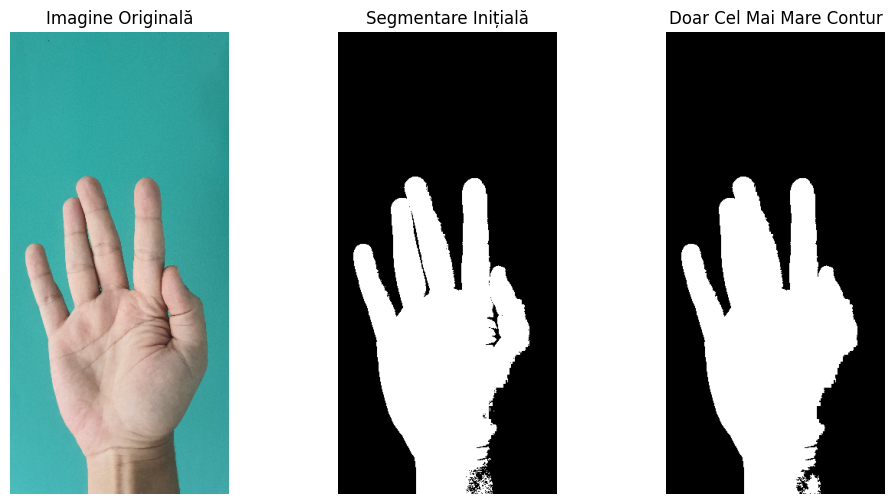

In [88]:
# Vizualizăm rezultatul comparativ pentru o imagine de test
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.imshow(te_im[0][0])
plt.title('Imagine Originală')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(test_segmented[0][0], cmap='gray')
plt.title('Segmentare Inițială')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(test_largest_contours[0][0], cmap='gray')
plt.title('Doar Cel Mai Mare Contur')
plt.axis('off')

plt.show()

In [89]:
def crop_to_bounding_rect(orig_img, contour_mask):
    # Convertim masca în format uint8 (0 sau 255)
    mask_uint8 = (contour_mask * 255).astype(np.uint8)

    # Găsim coordonatele dreptunghiului încadrator pentru regiunea albă
    x, y, w, h = cv2.boundingRect(mask_uint8)

    # Dacă s-a găsit un contur valid, decupăm imaginea originală
    if w > 0 and h > 0:
        cropped_img = orig_img[y:y+h, x:x+w]
    else:
        # În cazul puțin probabil în care nu există contur, returnăm imaginea originală intactă
        cropped_img = orig_img

    return cropped_img

# Cropăm toate imaginile din setul de train
train_cropped = []
for i in range(len(tr_im)):
    tmp = []
    for j in range(len(tr_im[0])):
        cropped = crop_to_bounding_rect(tr_im[i][j], train_largest_contours[i][j])
        tmp.append(cropped)
    train_cropped.append(tmp)

# Cropăm toate imaginile din setul de test
test_cropped = []
for i in range(len(te_im)):
    tmp = []
    for j in range(len(te_im[0])):
        cropped = crop_to_bounding_rect(te_im[i][j], test_largest_contours[i][j])
        tmp.append(cropped)
    test_cropped.append(tmp)

print("Toate imaginile au fost decupate cu succes conform dreptunghiului încadrator!")

Toate imaginile au fost decupate cu succes conform dreptunghiului încadrator!


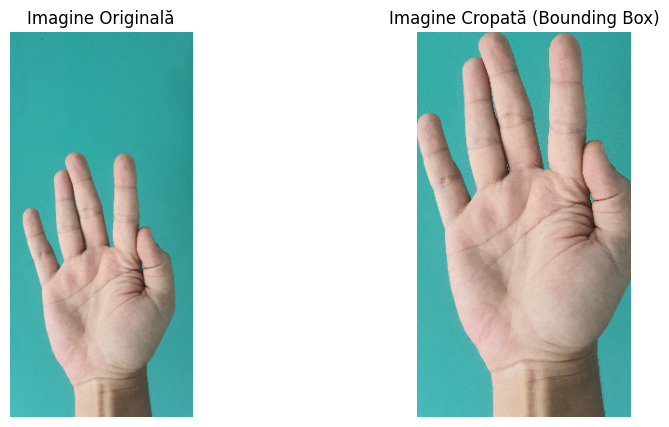

In [90]:
# Vizualizăm un exemplu din setul de test pentru a vedea rezultatul cropării
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(te_im[0][0])
plt.title('Imagine Originală')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(test_cropped[0][0])
plt.title('Imagine Cropată (Bounding Box)')
plt.axis('off')

plt.show()